# 4. Ethane: Symmetry in Calculations

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4/blob/main/book/04-Ethane/041-Ethane.ipynb)
:::

Ethane can **rotate** freely along the C&ndash;C bond. The lowest energy **conformation** is the *anti* (staggered) form and the highest energy is the *syn* (eclipsed) form. It is easy to get *Psi4* to optimize the *anti* structure, the software will **seek** the lowest energy state. How do we get the *syn* form? We could do this by **enforcing** symmetry.

## Learning Goals

This exercise will hopefully accomplish the following **goals** while learning new **skills**:

1.	We will manually **construct** *Z-matrices* for larger molecules and identify an internal coordinate that defines the torsion angle between the two methyl groups of ethane.
2.	We will use the **symmetry** of the *anti* and *syn* conformations to **lock** their conformations.
3.	We will determine optimized **structure** and the **energy** difference between the *syn* and *anti*-conformations and **compare** our results to literature values.
4.	We will **calculate** and **visualize** the molecular orbitals and the localized bonding orbitals of both conformations.

In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install packages only if needed
# Google Colab does not include every Python package
#
# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:                  # if the package exists import it, otherwise install it
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot style sheets from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/S2_classic2.mplstyle

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    plt.style.use("../../styles/tufte.mplstyle")

## Setting Up the Notebook

As in the previous chapters, the hidden **first code cell** imports *Psi4*, *py3Dmol*, *NumPy*, *pandas* and *Matplotlib* and applies the plot **style sheet**. You will see it when you open the notebook in *Jupyter*, *Visual Studio Code* or *Google Colab*.

```{admonition} Running this notebook in Google Colab
:class: dropdown
The first code cell checks whether the notebook is running in *Google Colab*. If it is, the cell **installs** *Psi4* for you. *Colab* does not come with *conda*, so the cell first installs it using a package called *condacolab*. This **restarts** the *Colab* session. When it has restarted, simply **run the first cell again**. It will then install *Psi4* with *conda* (*Psi4* cannot be installed with *pip*), install *py3Dmol* with *pip*, and download the plot style sheets from the book's *GitHub* repository. This takes a few minutes, and you must do it every time you start a new *Colab* session. On your own computer, the cell just imports the packages.
```

Next, we tell *Psi4* how much of the computer it may use, and set the options that we will need in this chapter.

In [2]:
psi4.set_memory("4 GB")
psi4.set_num_threads(4)

psi4.set_options({"scf_type": "pk",
                  "cubic_grid_spacing": [0.4, 0.4, 0.4],
                  "cubic_grid_overage": [3.0, 3.0, 3.0]})


  Memory set to   3.725 GiB by Python driver.
  Threads set to 4 by Python driver.


| Line | Notes |
| :---- | :---- |
| `"scf_type": "pk"` | Calculate the electron repulsion integrals **exactly**, as in the previous chapters. |
| `"cubic_grid_spacing"`, `"cubic_grid_overage"` | The spacing of the grid points (0.4 Bohr) and the extra space around the molecule (3.0 Bohr) for the **cube files** of orbitals that we will make near the end of the chapter. These are the same settings that we used for methane. |

### Some Helpful Tools

We will reuse the functions from the previous chapters and add **one new one** for measuring torsion angles. In the webbook, click on the code section to expand it. Run the cell below once.

In [3]:
def show_molecule(mol):
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

def bond_length(mol, i, j):
    xyz = mol.geometry().np * psi4.constants.bohr2angstroms
    return np.linalg.norm(xyz[i] - xyz[j])

def bond_angle(mol, i, j, k):
    xyz = mol.geometry().np
    a = xyz[i] - xyz[j]
    b = xyz[k] - xyz[j]
    cos_angle = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.degrees(np.arccos(cos_angle))

def dihedral(mol, i, j, k, l):
    xyz = mol.geometry().np
    b1 = xyz[j] - xyz[i]
    b2 = xyz[k] - xyz[j]
    b3 = xyz[l] - xyz[k]
    n1 = np.cross(b1, b2)
    n2 = np.cross(b2, b3)
    x = np.dot(n1, n2)
    y = np.dot(np.cross(n1, n2), b2) / np.linalg.norm(b2)
    return np.degrees(np.arctan2(y, x))

def plot_history(history, title):
    energies = np.array(history["energy"])
    delta_E = (energies - energies[-1]) * psi4.constants.hartree2kJmol
    steps = np.arange(1, len(energies) + 1)

    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
    ax.plot(steps, delta_E, color="black", linewidth=0.7, marker="o",
            markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
    ax.set_xticks(steps)
    ax.set_xlabel("Optimization step")
    ax.set_ylabel(r"$E - E_{final}$ (kJ/mol)")
    ax.set_title(title)
    plt.show()

def search_file(filename, text):
    with open(filename) as f:
        for number, line in enumerate(f, start=1):
            if text.lower() in line.lower():
                print(f"{number:6d}: {line.rstrip()}")

def show_orbital(mol, cube_file, isoval=0.05):
    with open(cube_file) as f:
        cube = f.read()
    view = py3Dmol.view(width=400, height=300)
    view.addModel(mol.save_string_xyz_file(), "xyz")
    view.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
    view.addVolumetricData(cube, "cube", {"isoval": isoval, "color": "#FFB3BA", "opacity": 0.85})
    view.addVolumetricData(cube, "cube", {"isoval": -isoval, "color": "#AEC6CF", "opacity": 0.85})
    view.setBackgroundColor("#f2f2f2")
    view.zoomTo()
    view.show()

| Function | What it does |
| :---- | :---- |
| `show_molecule(mol)` | Draws the molecule with *py3Dmol*. |
| `bond_length(mol, i, j)` | The distance between atoms `i` and `j` in **&Aring;ngstroms**. |
| `bond_angle(mol, i, j, k)` | The angle `i`&ndash;`j`&ndash;`k` in **degrees**, with `j` in the middle. |
| `dihedral(mol, i, j, k, l)` | **New.** The **torsion** (dihedral) angle `i`&ndash;`j`&ndash;`k`&ndash;`l` in degrees: the angle between the plane of atoms `i`, `j`, `k` and the plane of atoms `j`, `k`, `l`, looking down the `j`&ndash;`k` bond. The two cross products `n1` and `n2` are vectors **perpendicular** to the two planes. The angle between them is the torsion angle. `arctan2` also gives us its **sign** (clockwise or anticlockwise), from &minus;180&deg; to +180&deg;. |
| `plot_history(history, title)` | **Plots** the energy at each step of an optimization relative to the final energy. |
| `search_file(filename, text)` | **Prints** every line of a file that contains `text`. |
| `show_orbital(mol, cube_file, isoval)` | Draws an orbital from a **cube file** as two isosurfaces, pink for the `+isoval` phase and blue for the `-isoval` phase. |

```{note}
Remember that *Python* counts atoms from **zero**, but the *Z-matrix* counts from **one**. In this chapter, *Z-matrix* atom 6 is *Python* atom `5`. Dummy atoms would not be counted at all in *Python*, but we will not need any for ethane.
```

## Point Groups in Ethane

Each of the extreme cases in ethane has **symmetry**. They have **different** symmetry and so we can use that to our advantage. The symmetry of the *syn* conformation is *D<sub>3h</sub>* and for the *anti* it is *D<sub>3d</sub>*. If the optimization starts with that symmetry, it will end with that symmetry. This will enforce the *anti* (or *syn*) conformation for us. Using symmetry when possible will also **reduce the cost** of calculation.

In *GAMESS* we had to **declare** the point group (`DND 3` or `DNH 3`) and *GAMESS* kept the molecule in that point group during the optimization. *Psi4* **detects** the point group by itself. But, as we saw with ammonia and methane, *Psi4* only does its math in *D<sub>2h</sub>* and its **subgroups**. Neither *D<sub>3d</sub>* nor *D<sub>3h</sub>* is one of them. *Psi4* will use the largest subgroup it can.

| Conformation | Full point group | *Psi4* computational point group | Operations kept |
| :---- | :---- | :---- | :---- |
| *anti* | *D<sub>3d</sub>* | *C<sub>2h</sub>* | *E*, one *C<sub>2</sub>* axis, the **inversion** centre *i*, and the *&sigma;<sub>d</sub>* plane perpendicular to that axis |
| *syn* | *D<sub>3h</sub>* | *C<sub>2v</sub>* | *E*, one *C<sub>2</sub>* axis, the *&sigma;<sub>v</sub>* plane through the C&ndash;C bond and the ***&sigma;<sub>h</sub>*** plane that cuts the C&ndash;C bond in half |

Is that enough to lock the conformation? Yes! Look at the operations that **swap** the two methyl groups. The **inversion centre** in the middle of the C&ndash;C bond sends each hydrogen to the opposite side of the molecule *and* to the other carbon. The front methyl group is the back methyl group turned by 180&deg; (staggered). The **mirror plane** *&sigma;<sub>h</sub>* reflects each hydrogen straight across to the other carbon. The front methyl group is the back methyl group with no turn at all (eclipsed). As long as the optimizer keeps the inversion centre (or the mirror plane), the methyl groups **cannot** rotate. The three-fold axis is lost in the subgroup, so the three C&ndash;H bonds of a methyl group are not *forced* to be identical, but the forces on them are identical to numerical precision, so they stay that way. We will check.

## *Z-Matrix* for Ethane

We can start with a *Z-matrix* for ethane. Take note of how the two methyl groups are set up so that they **refer** to their own atoms as much as possible and there is only one coordinate that describes the bond **rotation**. That is the torsion angle on the line for atom 6, the angle between H6&ndash;C1 and C2&ndash;H3, looking down the C&ndash;C bond. Atoms 7 and 8 are then placed at &plusmn;120&deg; from atom 6, and atoms 4 and 5 at &plusmn;120&deg; from atom 3. Turn atom 6 and the whole back methyl group turns with it.

We will also use **variables** for the bond lengths and angles. All six C&ndash;H bonds share the variable `rCH` and all six H&ndash;C&ndash;C angles share `aHCC`. This guarantees that our *starting* structure is exactly *D<sub>3d</sub>* or *D<sub>3h</sub>*. Rather than typing the *Z-matrix* twice, we will write a small **function** that builds an ethane molecule with any torsion angle we ask for.

In [4]:
def make_ethane(torsion):
    return psi4.geometry(f"""
0 1
C
C  1  rCC
H  2  rCH  1  aHCC
H  2  rCH  1  aHCC  3   120.0
H  2  rCH  1  aHCC  3  -120.0
H  1  rCH  2  aHCC  3  {torsion}
H  1  rCH  2  aHCC  6   120.0
H  1  rCH  2  aHCC  6  -120.0

rCC  = 1.5
rCH  = 1.0
aHCC = 110.0
""")

ethane_anti = make_ethane(180.0)
ethane_anti.update_geometry()

print("Full point group:         ", ethane_anti.get_full_point_group())
print("Computational point group:", ethane_anti.schoenflies_symbol())
print(f"H3-C2-C1-H6 torsion: {dihedral(ethane_anti, 2, 1, 0, 5):.2f} degrees")
show_molecule(ethane_anti)

Full point group:          D3d
Computational point group: c2h
H3-C2-C1-H6 torsion: 180.00 degrees


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `def make_ethane(torsion):` | Defines a **function** that takes one number, the torsion angle, and returns a *Psi4* molecule. |
| `f"""..."""` | An ***f*-string**. *Python* replaces anything inside curly brackets with the value of that variable, so `{torsion}` becomes `180.0`. |
| `C` and `C 1 rCC` | Carbon 1 **exists**. Carbon 2 is a distance `rCC` from carbon 1. |
| `H 2 rCH 1 aHCC` | Hydrogen 3 is bonded to carbon 2, with an H&ndash;C&ndash;C angle `aHCC`. |
| `H 2 rCH 1 aHCC 3 120.0` | Hydrogens 4 and 5 are bonded to carbon 2 and turned &plusmn;120&deg; from hydrogen 3 around the C&ndash;C axis. They refer to **their own** methyl group. |
| `H 1 rCH 2 aHCC 3 {torsion}` | Hydrogen 6 is bonded to carbon 1. Its torsion angle **relative to hydrogen 3** is the only coordinate that connects the two methyl groups. This is the angle we will change. |
| `H 1 rCH 2 aHCC 6 120.0` | Hydrogens 7 and 8 are turned &plusmn;120&deg; from hydrogen **6**, not from hydrogen 3. When hydrogen 6 turns, they turn with it. |
| `rCC = 1.5` ... | The **starting** values of the variables: rough guesses, just like the *GAMESS* input. |
| `dihedral(ethane_anti, 2, 1, 0, 5)` | Measures the H3&ndash;C2&ndash;C1&ndash;H6 torsion. *Python* atoms `2`, `1`, `0`, `5` are *Z-matrix* atoms 3, 2, 1, 6. |

*Psi4* found the *D<sub>3d</sub>* point group without being told and will do its math in *C<sub>2h</sub>*, just as we predicted. The torsion angle measures 180&deg;, which is staggered. (Each hydrogen on carbon 1 is at 60&deg;, 180&deg; or 300&deg; from a hydrogen on carbon 2.)

```{note}
In *GAMESS*, this was a **two-step** process. A *Z-matrix* in `$DATA` makes *GAMESS* reorient the molecule and pick out the symmetry-unique atoms itself. The *GAMESS* manual warns that molecules with a three-fold axis often confuse that choice and recommends giving the symmetry-unique atoms directly (`COORD=UNIQUE`). So we first optimized the *Z-matrix* with the cheap semi-empirical AM1 method, then copied the two unique atoms (one C and one H) from that result into a new input file, with a list of 18 internal coordinates (`NZVAR=18`, `$ZMAT IZMAT`) so that *GAMESS* would report bond lengths and angles. *Psi4* has no semi-empirical methods and needs no such tricks. We give it the whole *Z-matrix* and go straight to HF/6-311++G(d,p).
```

## *anti*-Ethane

We will optimize at the HF/6-311++G(d,p) level of theory, the same level that we used for methane and the same as the *GAMESS* chapter.

Optimizer: Optimization complete!
Final energy: -79.25193458 Hartree
Steps taken:  5
Full point group: D3d
C-C length:  1.5271 Angstrom
C-H lengths: [ 1.08620000  1.08620000  1.08620000  1.08620000  1.08620000  1.08620000]
H-C-C angle: 111.19 degrees
H-C-H angle: 107.70 degrees
Torsion:     -180.00 degrees


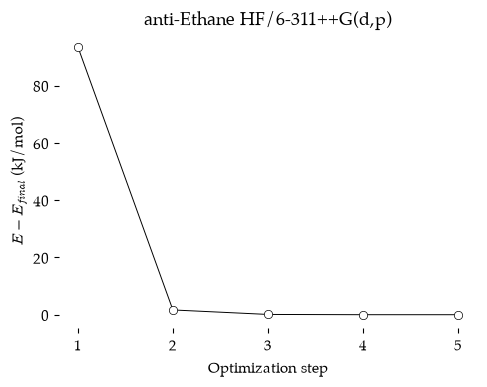

In [5]:
psi4.set_output_file("ethane_anti.out", False)

E_anti, hist_anti = psi4.optimize("hf/6-311++g(d,p)", molecule=ethane_anti, return_history=True)

print(f"Final energy: {E_anti:.8f} Hartree")
print("Steps taken: ", len(hist_anti["energy"]))
print("Full point group:", ethane_anti.get_full_point_group())
print(f"C-C length:  {bond_length(ethane_anti, 0, 1):.4f} Angstrom")
print("C-H lengths:", np.round([bond_length(ethane_anti, c, h) for c, h in [(1, 2), (1, 3), (1, 4), (0, 5), (0, 6), (0, 7)]], 4))
print(f"H-C-C angle: {bond_angle(ethane_anti, 2, 1, 0):.2f} degrees")
print(f"H-C-H angle: {bond_angle(ethane_anti, 2, 1, 3):.2f} degrees")
print(f"Torsion:     {dihedral(ethane_anti, 2, 1, 0, 5):.2f} degrees")

plot_history(hist_anti, "anti-Ethane HF/6-311++G(d,p)")

| Line | Notes |
| :---- | :---- |
| `"hf/6-311++g(d,p)"` | The same basis set as `GBASIS=N311 NGAUSS=6 NDFUNC=1 NPFUNC=1 DIFFSP=.TRUE. DIFFS=.TRUE.` in the *GAMESS* input file. |
| `for c, h in [(1, 2), (1, 3), ...]` | A **list comprehension** that measures all six C&ndash;H bonds. Each pair is (carbon, hydrogen) in *Python* numbering. `np.round(..., 4)` rounds the whole list to four decimal places. |
| `bond_angle(ethane_anti, 2, 1, 3)` | The H3&ndash;C2&ndash;H4 angle, with carbon 2 in the **middle**. |

The optimization took **five** steps and finished at &minus;79.25193458 Hartree. The full point group is still *D<sub>3d</sub>*: the methyl groups did not turn. All six C&ndash;H bonds are **identical** (1.0862 &Aring;), even though the *C<sub>2h</sub>* subgroup did not require it. The C&ndash;C bond is 1.5271 &Aring;, the H&ndash;C&ndash;C angle is 111.19&deg; and the H&ndash;C&ndash;H angle is 107.70&deg;, a little **smaller** than the tetrahedral 109.47&deg;. The torsion angle may print as +180&deg; or &minus;180&deg;. They are the same angle. Almost all of the energy drop happened in the first step, when our rough 1.5 &Aring; and 1.0 &Aring; guesses relaxed.

Now let us look at the convergence table in the output file.

In [6]:
search_file("ethane_anti.out", "~")

   450: 	----------------------------------------------------------------------------------------------~
   451: 	   Step    Total Energy     Delta E     Max Force     RMS Force      Max Disp      RMS Disp   ~
   452: 	----------------------------------------------------------------------------------------------~
   453: 	  Convergence Criteria     1.00e-06 *    3.00e-04 *             o    1.20e-03 *             o~
   454: 	----------------------------------------------------------------------------------------------~
   455: 	     1     -79.21631152   -7.92e+01      7.65e-02      3.58e-02 o    1.41e-01      6.69e-02 o  ~
   906: 	     2     -79.25130060   -3.50e-02      8.31e-03      3.94e-03 o    1.75e-02      9.33e-03 o  ~
  1356: 	     3     -79.25189935   -5.99e-04      1.75e-03      8.65e-04 o    4.53e-03      2.51e-03 o  ~
  1806: 	     4     -79.25193294   -3.36e-05      3.74e-04      1.88e-04 o    1.21e-03      5.79e-04 o  ~
  2255: 	     5     -79.25193458   -1.64e-06      7.

| Column | Notes |
| :---- | :---- |
| `Delta E` | The **change** in energy from the previous step. |
| `Max Force` | The largest **force** (slope of the energy) on any internal coordinate. |
| `Max Disp` | The largest **move** of any internal coordinate in that step. |

At step 5, the largest force (7.97 &times; 10<sup>&minus;5</sup>) and the largest displacement (1.92 &times; 10<sup>&minus;4</sup>) met their targets (`*`). The energy change (1.64 &times; 10<sup>&minus;6</sup> Hartree) did **not** quite meet its target of 1.0 &times; 10<sup>&minus;6</sup>, but *Psi4*'s default criteria only need the force plus **either** the energy change or the displacement. The optimization was declared complete.

How does this compare with `OPTTOL=0.0001` in the *GAMESS* input? *GAMESS* requires the largest gradient component to be below `OPTTOL` **and** the RMS gradient to be below one third of it (3.3 &times; 10<sup>&minus;5</sup>). Our final step has a largest force of 7.97 &times; 10<sup>&minus;5</sup> but an RMS force of 3.89 &times; 10<sup>&minus;5</sup>, so *GAMESS* would probably have taken one more step. The two programs also measure forces in different coordinates, so the criteria are **similar**, not identical. The structures will agree to about three decimal places, which is all we need.

Because we used a *Z-matrix* with **variables**, *Psi4* gives us back the optimized values of the variables at the end of the output file.

In [7]:
with open("ethane_anti.out") as f:
    lines = f.readlines()

start = next(i for i, line in enumerate(lines) if "Final optimized geometry" in line)
print("".join(lines[start:start + 20]))

    Final optimized geometry and variables:
    Molecular point group: c2h
    Full point group: D3d

    Geometry (in Angstrom), charge = 0, multiplicity = 1:

    C       
    C             1         rCC
    H             2         rCH      1        aHCC
    H             2         rCH      1        aHCC      3  120.000000
    H             2         rCH      1        aHCC      3 -120.000000
    H             1         rCH      2        aHCC      3  180.000000
    H             1         rCH      2        aHCC      6  120.000000
    H             1         rCH      2        aHCC      6 -120.000000

    aHCC      =  111.1870500105
    rCC       =    1.5271086162
    rCH       =    1.0861853442




*Psi4* gives us back our *Z-matrix* with the optimized values of the three variables: `rCC` = 1.5271 &Aring;, `rCH` = 1.0862 &Aring; and `aHCC` = 111.187&deg;. The torsion angles are unchanged. In *GAMESS* we had to supply a list of 18 internal coordinates (`NZVAR=18` and `IZMAT`) to get these numbers. Here the *Z-matrix* variables give us the C&ndash;C length, the C&ndash;H length and the H&ndash;C&ndash;C angle for **free**. The H&ndash;C&ndash;H angle is not in the *Z-matrix*, so we measured it with `bond_angle()` above.

Here is a summary of the calculated **data** at the HF/6-311++G(d,p) level.

| Coordinate       | Value           |
| :-------         | :-------        |
| C&ndash;C length       |    1.527 &Aring;      |
| C&ndash;H length       |    1.086 &Aring;      |
| H&ndash;C&ndash;C angle      |  111.2&deg;         |
| H&ndash;C&ndash;H angle      |  107.7&deg;         |
| Energy (Ha)      | &minus;79.25193458  |

The structure is **identical** to the *GAMESS* result to the precision shown. The energy is 0.00008 Hartree (0.2 *kJ/mol*) **higher** than the *GAMESS* energy of &minus;79.2520118 Hartree. That is not an error. *GAMESS* uses six **Cartesian** *d* functions on carbon by default, while *Psi4* uses five **spherical** *d* functions for the 6-311G family, so the *GAMESS* basis set is slightly bigger.

The absolute QM energy value is just a number until we compare it to a similar structure. In this case we will **compare** it to a very similar structure, the *syn* conformation. This is probably the best case scenario for calculating **relative** energies between two situations.

## *syn*-Ethane

The *syn* structure has *D<sub>3h</sub>* symmetry and the *Z-matrix* is **almost** identical. We just have to **change** the one coordinate that defines the **torsion** angle between the two methyl groups. This is the 6,1,2,3 torsion angle (the line for atom 6 of the *Z-matrix*). With our `make_ethane()` function, that is a single number.

Full point group:          D3h
Computational point group: c2v
Optimizer: Optimization complete!
Final energy: -79.24706290 Hartree
Steps taken:  5
Full point group: D3h
C-C length:  1.5411 Angstrom
C-H lengths: [ 1.08510000  1.08510000  1.08510000  1.08510000  1.08510000  1.08510000]
H-C-C angle: 111.63 degrees
H-C-H angle: 107.23 degrees
Torsion:     0.00 degrees


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

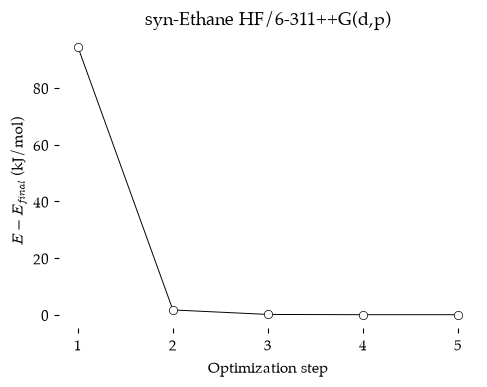

In [8]:
ethane_syn = make_ethane(0.0)
ethane_syn.update_geometry()

print("Full point group:         ", ethane_syn.get_full_point_group())
print("Computational point group:", ethane_syn.schoenflies_symbol())

psi4.set_output_file("ethane_syn.out", False)

E_syn, hist_syn = psi4.optimize("hf/6-311++g(d,p)", molecule=ethane_syn, return_history=True)

print(f"Final energy: {E_syn:.8f} Hartree")
print("Steps taken: ", len(hist_syn["energy"]))
print("Full point group:", ethane_syn.get_full_point_group())
print(f"C-C length:  {bond_length(ethane_syn, 0, 1):.4f} Angstrom")
print("C-H lengths:", np.round([bond_length(ethane_syn, c, h) for c, h in [(1, 2), (1, 3), (1, 4), (0, 5), (0, 6), (0, 7)]], 4))
print(f"H-C-C angle: {bond_angle(ethane_syn, 2, 1, 0):.2f} degrees")
print(f"H-C-H angle: {bond_angle(ethane_syn, 2, 1, 3):.2f} degrees")
print(f"Torsion:     {dihedral(ethane_syn, 2, 1, 0, 5):.2f} degrees")

show_molecule(ethane_syn)
plot_history(hist_syn, "syn-Ethane HF/6-311++G(d,p)")

| Line | Notes |
| :---- | :---- |
| `make_ethane(0.0)` | The same *Z-matrix* with a torsion of **0&deg;**: hydrogen 6 sits directly in front of hydrogen 3. |

*Psi4* found the *D<sub>3h</sub>* point group and used the *C<sub>2v</sub>* subgroup. The optimization took **five** steps and the molecule is still *D<sub>3h</sub>* at the end, with a torsion of 0.00&deg;. The symmetry held the methyl groups in the eclipsed position, even though this structure is the **top** of the rotation barrier, not the bottom of an energy well. All six C&ndash;H bonds are again identical (1.0851 &Aring;).

In *GAMESS* this step was more troublesome. *GAMESS* **aligned** the symmetry-unique atoms into a **different** plane for each point group (the *yz* plane for *D<sub>3d</sub>* and the *xz* plane for *D<sub>3h</sub>*), and simply changing the point group in the *anti* input file made the symmetry **fail**. *Psi4* builds the Cartesian coordinates from the *Z-matrix*, finds the point group and chooses its own orientation every time, so one changed number was all we needed.

Let us read the optimized variables from the output file.

In [9]:
with open("ethane_syn.out") as f:
    lines = f.readlines()

start = next(i for i, line in enumerate(lines) if "Final optimized geometry" in line)
print("".join(lines[start:start + 20]))

    Final optimized geometry and variables:
    Molecular point group: c2v
    Full point group: D3h

    Geometry (in Angstrom), charge = 0, multiplicity = 1:

    C       
    C             1         rCC
    H             2         rCH      1        aHCC
    H             2         rCH      1        aHCC      3  120.000000
    H             2         rCH      1        aHCC      3 -120.000000
    H             1         rCH      2        aHCC      3    0.000000
    H             1         rCH      2        aHCC      6  120.000000
    H             1         rCH      2        aHCC      6 -120.000000

    aHCC      =  111.6309276842
    rCC       =    1.5411394781
    rCH       =    1.0851498747




The optimized variables are `rCC` = 1.5411 &Aring;, `rCH` = 1.0851 &Aring; and `aHCC` = 111.631&deg;, and the torsion is still exactly 0&deg;.

By **examining** the output, a summary of the result for the *syn* conformation can be made.

| Coordinate   | Value         |
| :-------     | :-------      |
| C&ndash;C length   |   1.541 &Aring;     |
| C&ndash;H length   |   1.085 &Aring;     |
| H&ndash;C&ndash;C angle  | 111.6&deg;        |
| H&ndash;C&ndash;H angle  | 107.2&deg;        |
| Energy (Ha)  | &minus;79.24706290 |

Once again the structure matches the *GAMESS* result, and the energy is a little higher (by 0.00009 Hartree) for the same basis set reason.

We can now make some **comparisons**.

## Discussion

Here is the **data** gathered together so that we can explore the **differences** in bond lengths, angles and molecular energy. We will also save it as a JSON file.

In [10]:
delta_E = (E_syn - E_anti) * psi4.constants.hartree2kJmol

results = pd.DataFrame({
    "Conformer": ["syn (D3h)", "anti (D3d)"],
    "Energy (Eh)": [E_syn, E_anti],
    "Delta E (kJ/mol)": [delta_E, 0.0],
    "C-C (A)": [bond_length(ethane_syn, 0, 1), bond_length(ethane_anti, 0, 1)],
    "C-H (A)": [bond_length(ethane_syn, 1, 2), bond_length(ethane_anti, 1, 2)],
    "H-C-C (deg)": [bond_angle(ethane_syn, 2, 1, 0), bond_angle(ethane_anti, 2, 1, 0)],
    "H-C-H (deg)": [bond_angle(ethane_syn, 2, 1, 3), bond_angle(ethane_anti, 2, 1, 3)],
    "Steps": [len(hist_syn["energy"]), len(hist_anti["energy"])],
})

results.to_json("ethane_HF6311ppGdp.json", orient="records", indent=2)
results.round(4)

,Conformer,Energy (Eh),Delta E (kJ/mol),C-C (A),C-H (A),H-C-C (deg),H-C-H (deg),Steps
0,syn (D3h),-79.2471,12.7906,1.5411,1.0851,111.6309,107.2278,5
1,anti (D3d),-79.2519,0.0000,1.5271,1.0862,111.1871,107.7022,5


| Line | Notes |
| :---- | :---- |
| `(E_syn - E_anti) * psi4.constants.hartree2kJmol` | The energy **difference** in Hartree, converted to *kJ/mol*. A positive number means the *syn* form is **higher** in energy. |
| `results.to_json(...)` | Saves the table as a **JSON** file beside the notebook. |

Here is the summary.

| Coordinate   | *syn* conformer | *anti* conformer |
| :-------     | :-------      | :---------     |
| C&ndash;C length   |      1.541 &Aring;  |     1.527 &Aring;    |
| C&ndash;H length   |      1.085 &Aring;  |     1.086 &Aring;    |
| H&ndash;C&ndash;C angle  |    111.6&deg;     |   111.2&deg;       |
| H&ndash;C&ndash;H angle  |    107.2&deg;     |   107.7&deg;       |
| &Delta;E (kJ/mol)  |    +12.8      |     0          |

The C&ndash;C bond is **shorter** in the *anti* conformer, as expected. And the H&ndash;C&ndash;H angle was **larger**, as expected. In the *syn* conformer, the eclipsed hydrogens push the methyl groups **apart**: the C&ndash;C bond stretches by 0.014 &Aring; and the H&ndash;C&ndash;C angles open up by 0.44&deg;.

The *syn* conformer is 12.79 *kJ/mol* higher in energy. *GAMESS* gave 12.76 *kJ/mol* (both round to 12.8). The small difference in the basis sets nearly **cancels** when we subtract two very similar structures. This is the cancellation of errors that we hoped for in the first chapter.

## Molecular Orbitals

Now that we have both structures, let us look at their **orbitals**. We calculate a single-point energy for each optimized structure and keep the **wavefunction**. We also write *Molden* files so that you can open the orbitals in *Avogadro*. Each job gets its own output file so that the orbital list we search for later belongs to the final structure, not to the first step of the optimization.

In [11]:
psi4.set_output_file("ethane_anti_wfn.out", False)
E, wfn_anti = psi4.energy("hf/6-311++g(d,p)", molecule=ethane_anti, return_wfn=True)
psi4.molden(wfn_anti, "ethane_anti.molden")

psi4.set_output_file("ethane_syn_wfn.out", False)
E, wfn_syn = psi4.energy("hf/6-311++g(d,p)", molecule=ethane_syn, return_wfn=True)
psi4.molden(wfn_syn, "ethane_syn.molden")

for name in ["ethane_anti_wfn.out", "ethane_syn_wfn.out"]:
    with open(name) as f:
        lines = f.readlines()
    start = next(i for i, line in enumerate(lines) if "Doubly Occupied:" in line)
    print(name)
    print("".join(lines[start:start + 7]))

ethane_anti_wfn.out
    Doubly Occupied:                                                      

       1Ag   -11.210198     1Bu   -11.209595     2Ag    -1.019257  
       2Bu    -0.843904     1Au    -0.598085     3Bu    -0.598085  
       3Ag    -0.509374     1Bg    -0.488003     4Ag    -0.488003  

    Virtual:                                                              

ethane_syn_wfn.out
    Doubly Occupied:                                                      

       1A1   -11.209713     1B2   -11.209150     2A1    -1.015295  
       2B2    -0.846345     1B1    -0.596537     3A1    -0.596537  
       4A1    -0.508377     1A2    -0.486278     3B2    -0.486278  

    Virtual:                                                              



| Line | Notes |
| :---- | :---- |
| `E, wfn_anti = psi4.energy(..., return_wfn=True)` | A single-point energy of the optimized *anti* structure, returning the **wavefunction** as well. We already know the energy, so we just reuse the name `E`. |
| `psi4.molden(wfn_anti, "ethane_anti.molden")` | Writes the orbitals in *Molden* format for *Avogadro*. |
| `for name in [...]:` | Repeats the indented lines for **each** output file. |
| `lines[start:start + 7]` | The `Doubly Occupied` heading and the lines after it: the nine **occupied** orbitals, labelled by symmetry type, with their energies in Hartree. |

Each conformer has **nine** doubly occupied orbitals (18 electrons). The labels are the symmetry types of the *Psi4* computational point groups, *C<sub>2h</sub>* for *anti* and *C<sub>2v</sub>* for *syn*.

| MO | *anti* label | *anti* energy (Eh) | *syn* label | *syn* energy (Eh) | What it is |
| :-- | :-- | :-- | :-- | :-- | :-- |
| 1, 2 | 1Ag, 1Bu | &minus;11.2102, &minus;11.2096 | 1A1, 1B2 | &minus;11.2097, &minus;11.2092 | carbon 1*s* cores, in phase and out of phase |
| 3 | 2Ag | &minus;1.0193 | 2A1 | &minus;1.0153 | all in phase, mostly carbon 2*s* |
| 4 | 2Bu | &minus;0.8439 | 2B2 | &minus;0.8463 | carbon 2*s*, out of phase |
| 5, 6 | 3Bu, 1Au | &minus;0.5981 (&times;2) | 1B1, 3A1 | &minus;0.5965 (&times;2) | a **degenerate** pair |
| 7 | 3Ag | &minus;0.5094 | 4A1 | &minus;0.5084 | C&ndash;C &sigma; |
| 8, 9 | 4Ag, 1Bg | &minus;0.4880 (&times;2) | 1A2, 3B2 | &minus;0.4863 (&times;2) | the **degenerate** HOMOs |

Look at MOs 5 and 6, and MOs 8 and 9. They have **identical** energies but *different* symmetry labels. In the true point groups (*D<sub>3d</sub>* and *D<sub>3h</sub>*), each pair is a single **doubly degenerate** *e* set (*e<sub>u</sub>* and *e<sub>g</sub>* for *anti*, *e'* and *e''* for *syn*). The subgroups that *Psi4* uses have no two-dimensional symmetry types, so each degenerate pair is **split** across two labels. The orbital energies of the two conformers are very similar. In the eclipsed form, the HOMOs are slightly **higher** (by 0.0017 Hartree), and so is the C&ndash;C &sigma; orbital (by 0.0010 Hartree).

Let us **draw** the three highest occupied orbitals of each conformer.

In [12]:
for name, mol, wfn in [("anti", ethane_anti, wfn_anti), ("syn", ethane_syn, wfn_syn)]:
    folder = f"cube_{name}"
    Path(folder).mkdir(exist_ok=True)
    psi4.set_options({"cubeprop_tasks": ["orbitals"],
                      "cubeprop_orbitals": [7, 8, 9],
                      "cubeprop_filepath": folder})
    psi4.cubeprop(wfn)

    for cube_file in sorted(Path(folder).glob("Psi_a_*.cube")):
        print(name, cube_file.name)
        show_orbital(mol, cube_file)

anti Psi_a_7_3-Ag.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

anti Psi_a_8_1-Bg.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

anti Psi_a_9_4-Ag.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

... (2 outputs left out)

syn Psi_a_8_1-A2.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

syn Psi_a_9_3-B2.cube


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `for name, mol, wfn in [...]` | Repeats the work for both conformations. Each item in the list is a **group** of three things: a name, a molecule and a wavefunction. |
| `"cubeprop_orbitals": [7, 8, 9]` | The **three highest** occupied orbitals, counting from one in order of energy. |
| `sorted(Path(folder).glob("Psi_a_*.cube"))` | Finds the cube files that *Psi4* wrote, in order. The file name includes the orbital number and its **symmetry** label. |

Rotate the orbitals with your mouse. The first picture for each conformer is MO 7, with a large lobe of one phase **between** the two carbons: the C&ndash;C &sigma; bond, with some out-of-phase C&ndash;H character at each end. The other two are the degenerate **HOMOs**. Each looks like a pair of *p*-like lobes on each methyl group, made from the C&ndash;H bonds of that methyl group. The phase **changes** as we cross from one carbon to the other, so there is a **nodal plane** cutting the C&ndash;C bond in half. The HOMOs are **antibonding** between the two carbons (&pi;* type), while their lower partners, MOs 5 and 6, are the in-phase (&pi; type) combination.

Open `ethane_anti.molden` and `ethane_syn.molden` in *Avogadro* to see all of the orbitals, including MOs 5 and 6.

## Local Bonding Orbitals

The canonical MOs are spread over the whole molecule. To see the **bonds** of the Lewis structure, we localize the orbitals with the **Boys** method, as we did for methane. *GAMESS* used Edmiston&ndash;Ruedenberg localization (`LOCAL=RUEDNBRG`), which *Psi4* does not have. Boys and Edmiston&ndash;Ruedenberg orbitals are usually very similar for simple &sigma; bonds.

A localized orbital does not belong to any symmetry type, so we first make a ***C<sub>1</sub>*** copy of each optimized molecule and calculate its wavefunction.

In [13]:
local_energies = {}

for name, mol in [("anti", ethane_anti), ("syn", ethane_syn)]:
    mol_c1 = psi4.geometry(mol.save_string_xyz() + "symmetry c1\n")
    psi4.set_output_file(f"ethane_{name}_c1.out", False)
    E, wfn_c1 = psi4.energy("hf/6-311++g(d,p)", molecule=mol_c1, return_wfn=True)

    C_occ = wfn_c1.Ca_subset("AO", "OCC")
    boys = psi4.core.Localizer.build("BOYS", wfn_c1.basisset(), C_occ)
    boys.localize()
    L = boys.L.np

    F = wfn_c1.Fa().np
    eps_local = np.diag(L.T @ F @ L)
    local_energies[name] = eps_local
    print(name, "converged:", boys.converged)
    print("  Canonical MO energies (Eh):", np.round(wfn_c1.epsilon_a().np[:9], 4))
    print("  Local MO energies (Eh):    ", np.round(eps_local, 4))

    wfn_local = wfn_c1.c1_deep_copy(wfn_c1.basisset())
    wfn_local.Ca().np[:, :9] = L
    psi4.molden(wfn_local, f"ethane_{name}_local.molden")

    order = np.argsort(eps_local)
    cc = order[2] + 1
    ch = order[3] + 1

    folder = f"cube_{name}_local"
    Path(folder).mkdir(exist_ok=True)
    psi4.set_options({"cubeprop_tasks": ["orbitals"],
                      "cubeprop_orbitals": [int(cc), int(ch)],
                      "cubeprop_filepath": folder})
    psi4.cubeprop(wfn_local)

    print(f"  C-C bond: local orbital {cc}    C-H bond: local orbital {ch}")
    show_orbital(mol_c1, f"{folder}/Psi_a_{cc}_{cc}-A.cube")
    show_orbital(mol_c1, f"{folder}/Psi_a_{ch}_{ch}-A.cube")

anti converged: True
  Canonical MO energies (Eh): [-11.21020000 -11.20960000  -1.01930000  -0.84390000  -0.59810000
  -0.59810000  -0.50940000  -0.48800000  -0.48800000]
  Local MO energies (Eh):     [-11.17650000 -11.17650000  -0.65270000  -0.65270000  -0.65270000
  -0.65270000  -0.69530000  -0.65270000  -0.65270000]
  C-C bond: local orbital 7    C-H bond: local orbital 9


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

syn converged: True
  Canonical MO energies (Eh): [-11.20970000 -11.20910000  -1.01530000  -0.84630000  -0.59650000
  -0.59650000  -0.50840000  -0.48630000  -0.48630000]
  Local MO energies (Eh):     [-11.17620000 -11.17620000  -0.68950000  -0.65210000  -0.65210000
  -0.65210000  -0.65210000  -0.65210000  -0.65210000]
  C-C bond: local orbital 3    C-H bond: local orbital 7


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

| Line | Notes |
| :---- | :---- |
| `mol.save_string_xyz() + "symmetry c1\n"` | The optimized coordinates as text, with a line added that tells *Psi4* to use **no** symmetry. |
| `wfn_c1.Ca_subset("AO", "OCC")` | The coefficients of the nine **occupied** orbitals. |
| `psi4.core.Localizer.build("BOYS", ...)`, `boys.localize()` | Mixes the occupied orbitals until they are as **compact** as possible. |
| `np.diag(L.T @ F @ L)` | The **energy** of each local orbital, from the Fock matrix, as for methane. |
| `wfn_local.Ca().np[:, :9] = L` | A copy of the wavefunction with the nine local orbitals in place of the canonical ones, for drawing. |
| `order = np.argsort(eps_local)` | The local orbitals are in no particular order. `argsort` gives the **positions** of the orbitals sorted from lowest to highest energy. |
| `cc = order[2] + 1` | The two lowest are the carbon 1*s* cores. The **third** lowest is the C&ndash;C bond. We add one because `cubeprop_orbitals` counts from one. |
| `ch = order[3] + 1` | The fourth lowest is one of the six identical C&ndash;H bonds. Any one of them will do. |
| `int(cc)` | `argsort` gives *NumPy* integers. *Psi4* options want plain *Python* integers. |

Both localizations **converged**. Each conformer gives back two carbon 1*s* cores (&minus;11.18 Hartree), **one** C&ndash;C bond and **six** identical C&ndash;H bonds. Nine canonical MOs have become the nine pairs of electrons of the Lewis structure.

| Local orbital | *anti* energy (Eh) | *syn* energy (Eh) |
| :-- | :-- | :-- |
| C 1*s* (&times;2) | &minus;11.1765 | &minus;11.1762 |
| C&ndash;C &sigma; | &minus;0.6953 | &minus;0.6895 |
| C&ndash;H &sigma; (&times;6) | &minus;0.6527 | &minus;0.6521 |

The first picture for each conformer is the C&ndash;C bond, a single lobe between the carbons. The second is one C&ndash;H bond, a large lobe around a hydrogen. They look just like the C&ndash;H bonds of methane. Notice that the C&ndash;C bond orbital is 0.0058 Hartree (15 *kJ/mol*) **higher** in energy in the *syn* conformer. The local C&ndash;H orbitals barely change. Is the weaker C&ndash;C bond in the eclipsed form a cause of the barrier or a consequence of it? Keep that question in mind as you read the next section.

## The Controversy

The **literature** value for the ethane rotational energy barrier is 12.1 kJ/mol {cite:p}`Hirota1979`. We were pretty close with this low level of theory. There has been lots of **recent** work in this subject. Despite its simplicity, or because of it, it has been a focus for theoretical investigations. It started with an argument that molecular orbital interactions **stabilizing** the *anti* conformation were the **more important** contributor to the energy difference compared to electronic **repulsion** in the *syn* conformation {cite:p}`Goodman2001`. This is an idea that has been floated since the 1970s {cite:p}`Lowe1973` but it gained new life with the Nature publication. People **disagreed** and the fight was on {cite:p}`Bickelhaupt2004`. There are ongoing efforts to further refine the **model** for the energy difference {cite:p}`Baranac2015`, {cite:p}`Mo2011`.

## Summary

We have learned more about **constructing** a *Z-matrix* and applied this knowledge to design a *Z-matrix* for ethane within which we can easily create any **torsion angle** we wish. We wrapped it in a *Python* function so that a new conformation is one number away. We have observed how symmetry can **enforce** a given conformation while optimizing a structure, even though *Psi4* only uses the *C<sub>2h</sub>* and *C<sub>2v</sub>* subgroups of the true point groups. We have observed that the structures and the energy difference were reasonably close to **literature values**. We have drawn the **molecular orbitals** and the **local bonding orbitals** of both conformations.

In the exercise, you will also explore what happens when we remove the symmetry. Go to the instructions for the exercise and have fun.

## Exercise

Read the accompanying discussion above and then try the following activities.

### The Activities

**Repeat** the calculations described in the discussion. Open the *Molden* files of the optimized *D<sub>3h</sub>* and *D<sub>3d</sub>* structures in *Avogadro* and produce **images** of the molecules that display bond lengths and angles. Then produce images showing graphic representations of the unique **local bonding orbitals** (one C&ndash;C &sigma;-bond and one C&ndash;H &sigma;-bond will suffice) from the `_local.molden` files, or with `show_orbital()`. Report the energy difference for the two symmetries (*syn* and *anti*). Then present images for the bonding MOs for both symmetries. **Compare** their energies and their symmetries and discuss which best represent which local bonds (or combinations thereof).

Now **remove the symmetry** of the *syn* structure (no symmetry, *C<sub>1</sub>*, will allow free bond rotation). Run the optimization at the HF/6-311++G(d,p) level. Is the result *syn* or *anti*? **Discuss** the result. If the result remains *syn*, **propose** why *Psi4* could not bring itself to start the bond rotation. Now **change** the torsion angle by 0.1&deg;. Run the optimization **again**. Discuss the result. If it is still close to *syn*, try a bigger tip, such as 1&deg; or 5&deg;. **Compare** the energies of the *C<sub>1</sub>* *anti* and the *C<sub>1</sub>* *syn* structures. **Compare** bond lengths and angles as well. Do they match with the results that used symmetry?

````{admonition} Hint: turning off symmetry
:class: dropdown
Add one line to the end of the *Z-matrix* text in a copy of `make_ethane()`.

```text
symmetry c1
```

Check with `mol.schoenflies_symbol()` that the computational point group is now `c1`. *Psi4* will still report the **full** point group of the starting structure with `mol.get_full_point_group()`. It notices the symmetry, it just does not use it. Use `dihedral(mol, 2, 1, 0, 5)` before and after the optimization to see whether the methyl groups turned. Look at the `~` table in the output file. How large is the force at each step?
````

````{admonition} Hint: timing a calculation
:class: dropdown
*Python* can time anything.

```python
import time
start = time.time()
psi4.energy("hf/6-311++g(d,p)", molecule=mol)
print(f"{time.time() - start:.2f} seconds")
```
````

### The Report

Create a ONE-PAGE **document** that presents the images of the molecules and local and molecular orbitals described above. **Discuss** the relative energies of the orbitals. Are there any degenerate sets? How many nodal planes are in each set? Can you see how the local orbitals could be combined to make the molecular orbitals?

Did fixing the **symmetry** also fix the bond angles in the *syn* configuration? **Present** the consequences of removing the symmetry constraint. If there was no change in torsion when the symmetry was removed, **propose** a reason why. Did a slight tip in the torsion angle **solve** the problem? Why, or why not? Present the bond lengths and angles for the HF/6-311++G(d,p) structures without symmetry and discuss how they relate to the values with symmetry.

Try **running** energy calculations at the HF/6-311++G(d,p) level with and without symmetry and see if there is a difference in the **time** each calculation takes. Discuss the difference in time (there may be none as these are small molecules and modern personal computers are enormously powerful).

Include an **appendix** with the *Python* code that you used to build each molecule and run each calculation (please do not include any output files &ndash; there will be no trees left!). Use a fixed-width font.

```{warning} AI Statement
:class: dropdown
This page is an adaptation of the "Ethane" chapter of my [previous web book on using *GAMESS*](https://blinkletter.github.io/UsingGAMESS). About **a third** of the text is **my own work**, carried over word for word or lightly edited. This includes the introduction and learning goals, the point groups in ethane, most of the *Z-matrix* discussion, the summaries of the *anti* and *syn* results, the discussion of bond lengths and angles, "The Controversy", and the exercise and report. The **rest of the page** was written by an **LLM system** at my request. I asked it to convert the *GAMESS* jobs to *Python* code for *Psi4* at the HF/6-311++G(d,p) level, and to add the molecular orbitals and local bonding orbitals to the body of the chapter. All of the *Python* code, the line-by-line explanations of it, the discussion of the *Psi4* computational point groups, the analysis of the output files, the orbital sections and the commentary on the results were written by the LLM. The numbers quoted in the text come from running the calculations in *Psi4* 1.11.
```